In [ ]:
# ════════════════════════════════════════════════════════════════════
#  CÀI THƯ VIỆN CHO BÀI NÀY   (CAI THU VIEN CHO BAI NAY)
# ════════════════════════════════════════════════════════════════════
# Cell này chỉ cài những gói mà RIÊNG bài này cần, và chỉ cài gói nào
# đang thiếu. Nếu máy đã đủ thư viện thì nó không thay đổi gì.
#
# Phiên bản được chọn tự động theo Python đang chạy, vì pandas,
# scikit-learn và tensorflow không có bản dựng sẵn cho mọi phiên bản:
#     Python 3.10  →  bản đã dùng để tạo ra kết quả trong notebook này
#     Python 3.12  →  bản mới hơn, kết quả chạy lại có thể lệch nhẹ
import sys
from importlib.util import find_spec

PY312 = sys.version_info >= (3, 12)

# (tên module để kiểm tra, gói cho Python 3.10, gói cho Python 3.12)
REQUIRED = [
    ("numpy",     "numpy==1.26.4",         "numpy==1.26.4"),
    ("pandas",    "pandas==1.5.1",         "pandas==2.2.3"),
    ("sklearn",   "scikit-learn==1.2.0",   "scikit-learn==1.5.2"),
    ("matplotlib", "matplotlib==3.8.2",     "matplotlib==3.8.2"),
    ("seaborn",   "seaborn==0.13.1",       "seaborn==0.13.1"),
]

thieu = [(p312 if PY312 else p310) for mod, p310, p312 in REQUIRED
         if find_spec(mod) is None]

print(f"Python {sys.version.split()[0]}  |  bài này cần {len(REQUIRED)} gói")

if thieu:
    print("Đang cài", len(thieu), "gói còn thiếu:", ", ".join(thieu))
    try:
        from IPython import get_ipython
        _ip = get_ipython()
    except Exception:
        _ip = None
    if _ip is not None:
        _ip.run_line_magic("pip", "install --quiet " + " ".join(thieu))
    else:
        import subprocess
        subprocess.run([sys.executable, "-m", "pip", "install", "--quiet",
                        *thieu], check=False)
    print("\n✅ Cài xong. Hãy KHỞI ĐỘNG LẠI KERNEL rồi chạy lại từ đầu.")
else:
    print("✅ Đã đủ thư viện, không cần cài gì thêm.\n")
    import importlib.metadata as _md
    for mod, p310, p312 in REQUIRED:
        ten = (p312 if PY312 else p310).split("==")[0].split(">=")[0]
        try:
            print(f"   {ten:<16} {_md.version(ten)}")
        except Exception:
            print(f"   {ten:<16} (không đọc được phiên bản)")


In [1]:
# ============================================================
# TÌM HIỂU BỘ DỮ LIỆU FILE THỰC THI MÃ ĐỘC
# ============================================================

# 1. Import thư viện
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

In [2]:
# 2. Load dữ liệu
root_folder = Path.cwd()

df = pd.read_csv(
    root_folder.parent / "Dataset" / "malware-benignpe-files" / "Malware-Benign.csv"
)

print("Kích thước dataset:", df.shape)
print("\n5 dòng đầu tiên:")
print(df.head())

Kích thước dataset: (19611, 79)

5 dòng đầu tiên:
                                 Hash_md5_Name  e_magic  e_cblp  e_cp  e_crlc  \
0             a878ba26000edaac5c98eff4432723b3    23117     144     3       0   
1  VirusShare_ef9130570fddc174b312b2047f5f4cf0    23117     144     3       0   
2  VirusShare_ef84cdeba22be72a69b198213dada81a    23117     144     3       0   
3  VirusShare_6bf3608e60ebc16cbcff6ed5467d469e    23117     144     3       0   
4  VirusShare_2cc94d952b2efb13c7d6bbe0dd59d3fb    23117     144     3       0   

   e_cparhdr  e_minalloc  e_maxalloc  e_ss  e_sp  ...  SectionMaxChar  \
0          4           0       65535     0   184  ...      3758096608   
1          4           0       65535     0   184  ...      3791650880   
2          4           0       65535     0   184  ...      3221225536   
3          4           0       65535     0   184  ...      3224371328   
4          4           0       65535     0   184  ...      3227516992   

   SectionMainChar  Dire

In [3]:
# 3. Thông tin tổng quan
print("\nThông tin các cột:")
print(df.info())



Thông tin các cột:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19611 entries, 0 to 19610
Data columns (total 79 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Hash_md5_Name                 19611 non-null  object 
 1   e_magic                       19611 non-null  int64  
 2   e_cblp                        19611 non-null  int64  
 3   e_cp                          19611 non-null  int64  
 4   e_crlc                        19611 non-null  int64  
 5   e_cparhdr                     19611 non-null  int64  
 6   e_minalloc                    19611 non-null  int64  
 7   e_maxalloc                    19611 non-null  int64  
 8   e_ss                          19611 non-null  int64  
 9   e_sp                          19611 non-null  int64  
 10  e_csum                        19611 non-null  int64  
 11  e_ip                          19611 non-null  int64  
 12  e_cs                          19611 non-

In [4]:
# 4. Kiểm tra giá trị thiếu và trùng lặp
missing = df.isnull().sum()
print("\nGiá trị thiếu theo cột:")
print(missing[missing > 0] if any(missing > 0) else "Không có giá trị thiếu")

duplicates = df.duplicated().sum()
print(f"\nSố dòng trùng lặp: {duplicates}")


Giá trị thiếu theo cột:
Không có giá trị thiếu

Số dòng trùng lặp: 0


In [5]:
# 5. Xử lý dữ liệu cơ bản
# Xóa cột hash (không cần cho học máy)
if "Hash_md5_Name" in df.columns:
    df = df.drop(columns=["Hash_md5_Name"])

# Xóa dòng trùng
df = df.drop_duplicates()

# Điền giá trị thiếu bằng median cho các cột số
numeric_cols = df.select_dtypes(include=np.number).columns
for col in numeric_cols:
    df[col] = df[col].fillna(df[col].median())

print(f"\nSau xử lý: {df.shape[0]} dòng, {df.shape[1]} cột")


Sau xử lý: 16640 dòng, 78 cột


In [6]:
# 6. Chuẩn hóa dữ liệu (Min-Max Scaling)
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df[numeric_cols]), columns=numeric_cols)
print("\nDữ liệu sau chuẩn hóa (5 dòng đầu):")
print(df_scaled.head())


Dữ liệu sau chuẩn hóa (5 dòng đầu):
   e_magic    e_cblp      e_cp  e_crlc  e_cparhdr  e_minalloc  e_maxalloc  \
0      0.0  0.002422  0.000047     0.0   0.000092         0.0         1.0   
1      0.0  0.002422  0.000047     0.0   0.000092         0.0         1.0   
2      0.0  0.002422  0.000047     0.0   0.000092         0.0         1.0   
3      0.0  0.002422  0.000047     0.0   0.000092         0.0         1.0   
4      0.0  0.002422  0.000047     0.0   0.000092         0.0         1.0   

   e_ss      e_sp  e_csum  ...  SectionMaxChar  SectionMainChar  \
0   0.0  0.002811     0.0  ...        0.833333              0.0   
1   0.0  0.002811     0.0  ...        0.843750              0.0   
2   0.0  0.002811     0.0  ...        0.666667              0.0   
3   0.0  0.002811     0.0  ...        0.667643              0.0   
4   0.0  0.002811     0.0  ...        0.668620              0.0   

   DirectoryEntryImport  DirectoryEntryImportSize  DirectoryEntryExport  \
0              0.01190

In [7]:
# 7. Thống kê mô tả nhanh
print("\nThống kê mô tả các đặc trưng chính:")
print(df_scaled.describe().T[['mean', 'std', 'min', 'max']].head(10))


Thống kê mô tả các đặc trưng chính:
                mean       std  min  max
e_magic     0.000000  0.000000  0.0  0.0
e_cblp      0.003115  0.017878  0.0  1.0
e_cp        0.001309  0.024699  0.0  1.0
e_crlc      0.000878  0.020230  0.0  1.0
e_cparhdr   0.000974  0.021358  0.0  1.0
e_minalloc  0.000968  0.022543  0.0  1.0
e_maxalloc  0.975712  0.150343  0.0  1.0
e_ss        0.000200  0.011258  0.0  1.0
e_sp        0.003549  0.020450  0.0  1.0
e_csum      0.000529  0.017136  0.0  1.0


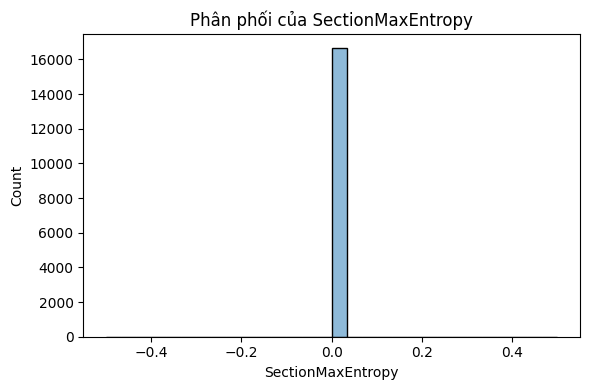

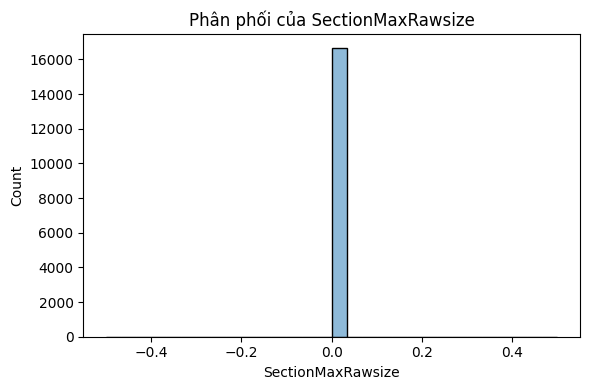

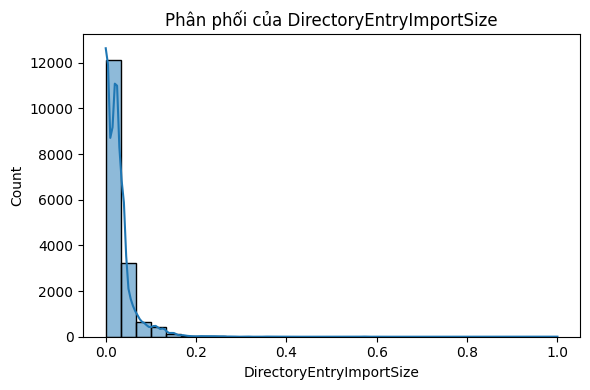

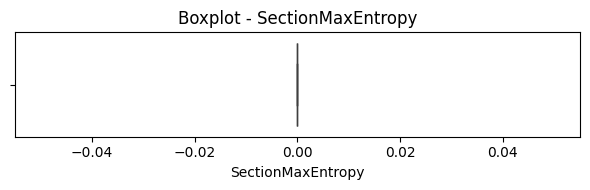

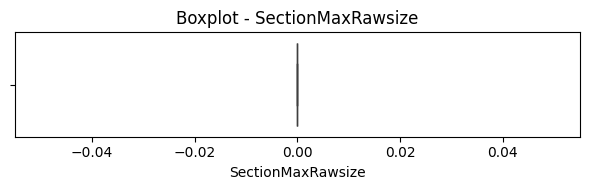

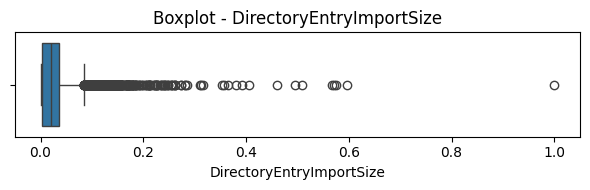

In [8]:
# 8. Trực quan hóa đơn giản
# Chọn một vài đặc trưng tiêu biểu
features_to_plot = ['SectionMaxEntropy', 'SectionMaxRawsize', 'DirectoryEntryImportSize']

# Histogram
for feat in features_to_plot:
    if feat in df_scaled.columns:
        plt.figure(figsize=(6,4))
        sns.histplot(df_scaled[feat], bins=30, kde=True)
        plt.title(f'Phân phối của {feat}')
        plt.tight_layout()
        plt.show()

# Boxplot để phát hiện outlier
for feat in features_to_plot:
    if feat in df_scaled.columns:
        plt.figure(figsize=(6,2))
        sns.boxplot(x=df_scaled[feat])
        plt.title(f'Boxplot - {feat}')
        plt.tight_layout()
        plt.show()

In [9]:
# Chỉ lấy các cột số, loại bỏ cột nhãn (Malware) để tránh rò rỉ nhãn vào phân tích tương quan
# (bản gốc chỉ kiểm tra tên cột 'legitimate', không tồn tại trong dataset này, nên nhãn 'Malware'
#  từng bị lọt vào numeric_df và ảnh hưởng tới kết quả phân tích)
numeric_df = df.select_dtypes(include=np.number)
if 'Malware' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['Malware'])

print("Số cột số (đã loại cột nhãn Malware):", numeric_df.shape[1])

# Tính ma trận tương quan
corr = numeric_df.corr()

# Lấy giá trị tuyệt đối
corr_matrix = corr.abs()

# Chỉ lấy tam giác trên của ma trận
upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

# Sắp xếp giảm dần
top_corr = upper.stack().sort_values(ascending=False)

print("\nTop 5 cặp đặc trưng có tương quan cao nhất:")
print(top_corr.head(5))

Số cột số (đã loại cột nhãn Malware): 77

Top 5 cặp đặc trưng có tương quan cao nhất:
Machine                      Magic                          1.000000
NumberOfSections             SectionsLength                 0.999974
SectionMinRawsize            SectionMinVirtualsize          0.999528
MajorOperatingSystemVersion  MinorOperatingSystemVersion    0.903224
SizeOfOptionalHeader         Magic                          0.894642
dtype: float64


In [10]:
# Đặc trưng có phương sai lớn nhất (biến động nhiều)
# Loại bỏ cột nhãn 'Malware' khỏi df_scaled trước khi tính phương sai, tránh nhãn tự "thắng"
# vì bản chất là biến nhị phân có phương sai riêng, không phản ánh mức biến động của một đặc trưng thật.
feature_variance = (
    df_scaled.drop(columns=['Malware'], errors='ignore')
    .var()
    .sort_values(ascending=False)
)
print("\nTop 5 đặc trưng có phương sai lớn nhất:")
print(feature_variance.head(5))


Top 5 đặc trưng có phương sai lớn nhất:
Magic                 0.125650
Machine               0.125649
DllCharacteristics    0.081904
FileAlignment         0.075067
SectionMinEntropy     0.052240
dtype: float64


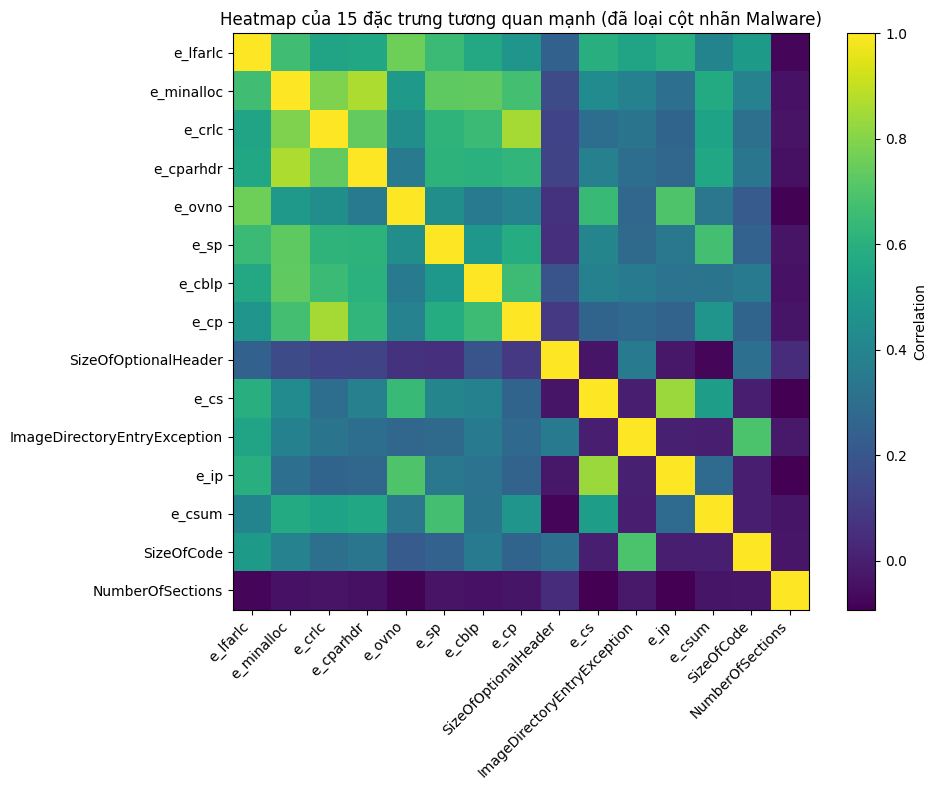

In [11]:
numeric_df = df.select_dtypes(include=np.number)

# SỬA LỖI: tên cột nhãn thực tế trong dataset là 'Malware', không phải 'legitimate'.
# Điều kiện gốc kiểm tra 'legitimate' luôn sai (cột này không tồn tại) nên cột nhãn
# chưa từng bị loại bỏ trước khi vẽ heatmap tương quan — gây rò rỉ nhãn vào phân tích.
if 'Malware' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['Malware'])

corr = numeric_df.corr().abs()

# Chọn 15 đặc trưng có tổng tương quan lớn nhất
top_features = corr.sum().sort_values(ascending=False).head(15).index

corr_top = numeric_df[top_features].corr()

plt.figure(figsize=(10, 8))
plt.imshow(corr_top)

plt.colorbar(label='Correlation')

plt.xticks(range(len(top_features)),
           top_features,
           rotation=45,
           ha='right')

plt.yticks(range(len(top_features)),
           top_features)

plt.title('Heatmap của 15 đặc trưng tương quan mạnh (đã loại cột nhãn Malware)')
plt.tight_layout()
plt.show()